# ASL Citizen SLR — Green Computing, Model 2/5: ResNet-50 (CNN, Heavy)

**Course:** CSE 407 — Green Computing
**Paper:** *Quantifying the Carbon Cost of Accuracy: An Energy-Aware Comparison of CNN and Transformer Architectures for Word-Level Sign Language Recognition*
**This notebook is 2 of 5** in the model family requested by faculty feedback on the proposal.

## Changelog / where this fits

### Relationship to notebook 1 (MobileNetV3-Small)
This is the **heavy** member of the CNN pair from faculty suggestion 1 (MobileNetV3-Small vs.
ResNet-50). Everything is structurally identical to notebook 1 — same cache, same manifest/
top-K logic, same per-frame-2D-CNN-then-temporal-average-pooling model shape, same training
hyperparameters, same green-computing accounting — **only the backbone changed**. That's
deliberate: the proposal's own methodology (Section V-A) says a fixed dataset and consistent
training protocol across architectures is what isolates architecture as the independent
variable, so nothing except `CONFIG.BACKBONE` / Section 5 should differ between this notebook
and notebook 1.

### The one structural difference: freeze granularity
MobileNetV3-Small exposes a flat list of inverted-residual blocks, so notebook 1 froze all but
the last `N` blocks. ResNet-50's natural granularity is its 4 named residual stages
(`layer1`–`layer4`). This notebook freezes everything before `layer4` and leaves `layer4` (+ the
new classification head) trainable — same partial-freeze *principle* as notebook 1, expressed at
ResNet-50's own structure rather than forcing MobileNetV3's block-counting scheme onto it.

### Reminders (same as notebook 1, repeated here since notebooks are read standalone)
1. **`CONFIG.TOP_K_CLASSES = 100`**, **`GRID_CARBON_INTENSITY_KG_PER_KWH = 0.475`**, and
   **`EXPECTED_INFERENCE_VOLUME = 100_000`** must stay identical across all 5 notebooks in the
   family — they're already set to match notebook 1 here. Don't tune them per-model.
2. **Not resumable across sessions**, on purpose — a resumed run would start a fresh
   `codecarbon` tracker and silently undercount total training energy, which is this notebook's
   actual research output. Run start-to-finish in one Kaggle session.
3. **ResNet-50 is heavier than MobileNetV3-Small** — expect a noticeably longer wall-clock
   training time and higher GPU memory use at the same `CONFIG.BATCH_SIZE=8` (16 frames/clip
   through a 25M-parameter backbone vs. a 2.5M-parameter one). If you hit an out-of-memory error
   on the Kaggle GPU, that's worth recording as a data point too — a heavier CNN needing a
   smaller batch size (or gradient accumulation) to fit is itself part of the accuracy-vs-cost
   story this paper is making, so note it rather than just quietly shrinking the batch size and
   moving on.
4. This is scaffolding for the paper, not the paper. It produces one more
   `green_metrics_*.json` model card, matching notebook 1's schema.

## 1. Setup & Imports

In [1]:
# --- One-time install of green-computing / profiling packages not preinstalled on Kaggle ---
import subprocess
import sys

for _pkg, _import_name in [("codecarbon", "codecarbon"), ("thop", "thop")]:
    try:
        __import__(_import_name)
    except ImportError:
        print(f"Installing {_pkg} ...")
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", _pkg], check=False)

import csv
import json
import math
import random
import time
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from sklearn.metrics import precision_recall_fscore_support
import torchvision

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 110

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

print(f"Torch: {torch.__version__}")
print(f"Torchvision: {torchvision.__version__}")
print(f"Device: {DEVICE}")


Installing codecarbon ...
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 396.9/396.9 kB 12.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 71.0/71.0 kB 5.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 155.6/155.6 kB 11.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.0/8.0 MB 100.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 96.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.7/4.7 MB 110.4 MB/s eta 0:00:00


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-adk 1.29.0 requires google-cloud-bigquery-storage>=2.0.0, which is not installed.
sigstore 4.3.0 requires cryptography<49,>=42, but you have cryptography 50.0.0 which is incompatible.
pydrive2 1.21.3 requires cryptography<44, but you have cryptography 50.0.0 which is incompatible.
pyopenssl 24.2.1 requires cryptography<44,>=41.0.5, but you have cryptography 50.0.0 which is incompatible.


Installing thop ...
Torch: 2.10.0+cu128
Torchvision: 0.25.0+cu128
Device: cuda


## 1b. Hardware & Software Environment

Captured directly so energy/carbon figures in this notebook can be sanity-checked and reproduced (paper review Major Issue #4).

In [2]:
# --- Hardware / software environment capture (Green-Computing review fix #4) ---
# CodeCarbon's energy figures are software-based power *estimates*; a reader cannot judge
# their reliability, or reproduce this run, without knowing what hardware and software stack
# produced them. Captured once per run and carried into the model card / multi-seed report.
import platform

HARDWARE_INFO = {
    "torch_version": torch.__version__,
    "cuda_version_torch_built_with": torch.version.cuda,
    "cudnn_version": torch.backends.cudnn.version() if torch.cuda.is_available() else None,
    "python_version": platform.python_version(),
    "platform": platform.platform(),
    "cpu_count_logical": __import__("os").cpu_count(),
    "gpu_available": torch.cuda.is_available(),
}

if torch.cuda.is_available():
    _gpu_props = torch.cuda.get_device_properties(0)
    HARDWARE_INFO.update({
        "gpu_name": torch.cuda.get_device_name(0),
        "gpu_count": torch.cuda.device_count(),
        "gpu_total_memory_gb": round(_gpu_props.total_memory / (1024**3), 2),
        "gpu_capability": f"{_gpu_props.major}.{_gpu_props.minor}",
    })
else:
    HARDWARE_INFO.update({"gpu_name": None, "gpu_count": 0, "gpu_total_memory_gb": None, "gpu_capability": None})

# Best-effort CPU/RAM info via psutil if available (Kaggle usually has it); degrade gracefully.
try:
    import psutil
    HARDWARE_INFO["ram_total_gb"] = round(psutil.virtual_memory().total / (1024**3), 2)
except ImportError:
    HARDWARE_INFO["ram_total_gb"] = None

print("Hardware / software environment for this run:")
for k, v in HARDWARE_INFO.items():
    print(f"  {k}: {v}")
print()
print("NOTE: this is the actual execution environment of THIS run. The grid carbon-intensity "
      "constant in Section 10 (Google Cloud us-central1, cited) is a fixed methodological "
      "assumption applied uniformly across the 5-model family (paper Section 3.4/6) -- it is "
      "NOT necessarily the grid this specific session's hardware is physically attached to. "
      "If this notebook is run on infrastructure known to sit in a specific region, replace "
      "CONFIG.GRID_CARBON_INTENSITY_KG_PER_KWH with that region's cited figure and relabel "
      "reported CO2e figures accordingly -- see the paper review's Major Issue #5.")


Hardware / software environment for this run:
  torch_version: 2.10.0+cu128
  cuda_version_torch_built_with: 12.8
  cudnn_version: 91002
  python_version: 3.12.13
  platform: Linux-6.12.90+-x86_64-with-glibc2.35
  cpu_count_logical: 4
  gpu_available: True
  gpu_name: Tesla T4
  gpu_count: 2
  gpu_total_memory_gb: 14.56
  gpu_capability: 7.5
  ram_total_gb: 31.35

NOTE: this is the actual execution environment of THIS run. The grid carbon-intensity constant in Section 10 (Google Cloud us-central1, cited) is a fixed methodological assumption applied uniformly across the 5-model family (paper Section 3.4/6) -- it is NOT necessarily the grid this specific session's hardware is physically attached to. If this notebook is run on infrastructure known to sit in a specific region, replace CONFIG.GRID_CARBON_INTENSITY_KG_PER_KWH with that region's cited figure and relabel reported CO2e figures accordingly -- see the paper review's Major Issue #5.


## 2. Green-Computing & Model Configuration

In [3]:
class CONFIG:
    WORK_DIR = Path("/kaggle/working")

    # ---- update these to match your mounted paths -- identical to notebook 1
    # (MobileNetV3) since this is the same ASL Citizen cache, just a different
    # backbone reading from it ----
    CACHE_DIRS = [
        Path("/kaggle/input/notebooks/aniruddha2022/asl-shared-cache-building-id00/feature_cache_shard_0"),
        Path("/kaggle/input/notebooks/redoanmozumder/asl-shared-cache-building-id02/feature_cache_shard_2"),
        Path("/kaggle/input/notebooks/pranaysahaps/asl-shared-cache-building-id01/feature_cache_shard_1"),
    ]
    SPLITS_DIR = Path("/kaggle/input/datasets/pranaysahaps/asl-citizen/splits")

    MODEL_TAG = "resnet50_cnn_heavy"
    CHECKPOINT_DIR = WORK_DIR / f"checkpoints_{MODEL_TAG}"
    OUTPUT_DIR = WORK_DIR / f"green_report_{MODEL_TAG}"

    # ---- Kept IDENTICAL to notebook 1 (MobileNetV3) on purpose. The proposal's own
    # methodology (Section V-A) says a fixed dataset and consistent training protocol --
    # identical epochs, batch size, hardware -- is what isolates architecture as the
    # independent variable. Changing any of these here would confound the CNN-vs-CNN
    # (light-vs-heavy) comparison this notebook exists to make. ----
    TOP_K_CLASSES = 100
    FRAME_COUNT = 16
    APPEARANCE_STREAM_IDX = 0
    IMAGE_SIZE = 224

    # ---- Model: ResNet-50, CNN family, heavier member (vs. notebook 1's MobileNetV3-Small) ----
    BACKBONE = "resnet50"
    # ResNet-50 doesn't have the same flat block list MobileNetV3 does -- its natural
    # unfreeze granularity is its 4 named residual stages (layer1..layer4). Unfreezing
    # from "layer4" (the last stage) onward is the same partial-freeze *principle*
    # notebook 1 used (protect ImageNet-pretrained weights from a tiny per-class WLSR
    # dataset, only let the last stage adapt), just expressed at ResNet-50's natural
    # granularity rather than MobileNetV3's block-count granularity.
    UNFREEZE_FROM_LAYER = "layer4"

    # ---- Training -- identical to notebook 1, see note above ----
    BATCH_SIZE = 8
    NUM_WORKERS = 2
    LR = 1e-4
    WEIGHT_DECAY = 3e-4
    GRAD_CLIP_NORM = 0.5
    LABEL_SMOOTHING = 0.1

    EPOCHS_FULL = 30
    MIN_EPOCHS_BEFORE_STOPPING = 15
    EARLY_STOPPING_PATIENCE = 6

    ACCURACY_GATE_THRESHOLD = 0.60  # soft reference point, not a hard requirement
    # The 60% figure above is author-chosen, not externally justified (paper review Minor
    # Issue #7). Rather than rest deployment conclusions on one unjustified line, the
    # deployment-readiness discussion (Section 10b) is reported parametrically across this
    # range so the reader can see whether the recommendation is threshold-sensitive.
    ACCURACY_GATE_THRESHOLDS_FOR_SENSITIVITY = [0.50, 0.60, 0.70]

    SEED = 42
    # Repeated-seed runs for statistical validity (paper review Major Issue #2: every
    # comparative claim in the original single-run version rests on n=1 per model).
    # SEED remains the default/primary seed (used by the single detailed run in Sections
    # 7-9 with full training curves); SEEDS is the full set repeated in the new Section 9b
    # for mean +/- SD reporting. Kept short (3) so the added compute stays tractable --
    # extend if compute budget allows.
    SEEDS = [42, 123, 2024]
    DEVICE = DEVICE

    # ---- Green computing accounting -- identical constants to notebook 1. These MUST
    # stay the same across all 5 notebooks or the cross-model comparison is meaningless. ----
    GRID_CARBON_INTENSITY_KG_PER_KWH = 0.41272  # Google Cloud us-central1, 2024 (412.72 gCO2eq/kWh) -- see notebook 1, Section 2, for the full citation/caveat note
    EXPECTED_INFERENCE_VOLUME = 100_000

    # Sensitivity range for the lifecycle-carbon-per-inference metric (paper review
    # Recommended fix: the 100,000-inference figure is not sensitivity-tested in the
    # original submission). eta_life is reported at each of these volumes, not just the
    # single point assumption above, so the ranking in Section 10 can be checked for
    # stability across plausible deployment scales.
    DEPLOYMENT_VOLUME_SENSITIVITY = [10_000, 100_000, 1_000_000]
    INFERENCE_PROFILING_PASSES = 3


def seed_everything(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


seed_everything(CONFIG.SEED)
CONFIG.CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
CONFIG.OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Model tag: {CONFIG.MODEL_TAG}")
print(f"Device: {CONFIG.DEVICE}")
print(f"Top-K classes: {CONFIG.TOP_K_CLASSES}")


Model tag: resnet50_cnn_heavy
Device: cuda
Top-K classes: 100


## 3. Build the Manifest & Apply the Top-K Class Filter

In [4]:
cache_index = {}
for shard_dir in CONFIG.CACHE_DIRS:
    assert shard_dir.exists(), f"Cache shard not found: {shard_dir} -- update CONFIG.CACHE_DIRS"
    for f in shard_dir.glob("*.npz"):
        cache_index[f.stem] = f
print(f"Total cached .npz files across {len(CONFIG.CACHE_DIRS)} shards: {len(cache_index)}")

split_files = {
    "train": CONFIG.SPLITS_DIR / "train.csv",
    "val": CONFIG.SPLITS_DIR / "val.csv",
    "test": CONFIG.SPLITS_DIR / "test.csv",
}
rows, all_glosses = [], set()
for subset, csv_path in split_files.items():
    assert csv_path.exists(), f"Missing split file: {csv_path}"
    with open(csv_path, newline="", encoding="utf-8") as f:
        reader = csv.DictReader(f)
        for row in reader:
            video_id = Path(row["Video file"]).stem
            gloss = row["Gloss"]
            all_glosses.add(gloss)
            if video_id in cache_index:
                rows.append((video_id, gloss, subset))

class_list_full = sorted(all_glosses)
class_to_idx_full = {g: i for i, g in enumerate(class_list_full)}

nslt_data_full = {}
for video_id, gloss, subset in rows:
    nslt_data_full[video_id] = {"action": [class_to_idx_full[gloss], 0, 0], "subset": subset}

print(f"Cached rows matched against splits: {len(rows)}")
print(f"Full ASL Citizen vocabulary present in cache: {len(class_list_full)} classes")

# --- top-K filter, identical remap logic to the Capstone notebooks' PILOT_MODE cell ---
class_video_counts = Counter(v["action"][0] for v in nslt_data_full.values())
top_k_old_indices = [c for c, _ in class_video_counts.most_common(CONFIG.TOP_K_CLASSES)]
top_k_old_indices_set = set(top_k_old_indices)
old_to_new_idx = {old_idx: new_idx for new_idx, old_idx in enumerate(top_k_old_indices)}

nslt_data = {
    vid: {"action": [old_to_new_idx[meta["action"][0]], 0, 0], "subset": meta["subset"]}
    for vid, meta in nslt_data_full.items()
    if meta["action"][0] in top_k_old_indices_set
}
class_list = {old_to_new_idx[old]: class_list_full[old] for old in top_k_old_indices}
NUM_CLASSES = len(class_list)

subset_counts = Counter(v["subset"] for v in nslt_data.values())
print(f"\nTop-{CONFIG.TOP_K_CLASSES} filter applied -- NUM_CLASSES: {NUM_CLASSES}")
print(f"Videos remaining: {len(nslt_data)} across splits {dict(subset_counts)}")

per_class_counts = Counter(v["action"][0] for v in nslt_data.values())
print(f"Videos/class (post-filter, all splits combined): "
      f"min={min(per_class_counts.values())} median={int(np.median(list(per_class_counts.values())))} "
      f"max={max(per_class_counts.values())}")


Total cached .npz files across 3 shards: 63550
Cached rows matched against splits: 63550
Full ASL Citizen vocabulary present in cache: 2731 classes

Top-100 filter applied -- NUM_CLASSES: 100
Videos remaining: 3200 across splits {'train': 1434, 'val': 357, 'test': 1409}
Videos/class (post-filter, all splits combined): min=32 median=32 max=32


### 3b. Signer-Independence Check

Verifies whether the pre-built train/val/test split is signer-disjoint (paper review Major Issue #1) before any model is trained on it.

In [5]:
# --- Signer-independence check for the train/val/test split (paper review Major Issue #1) ---
# ASL Citizen has 52 distinct signers. If the same signer appears in both train and test,
# accuracy is inflated by signer-specific visual cues (clothing, background, hand-shape
# idiosyncrasies) rather than sign semantics -- a leakage risk the original submission never
# checked. This cell re-reads the split CSVs looking for a participant/signer identifier and
# reports whether the pre-built splits in CONFIG.SPLITS_DIR are signer-disjoint.

POSSIBLE_SIGNER_COLUMNS = [
    "Participant ID", "ParticipantID", "Participant", "Signer ID", "SignerID",
    "Signer", "signer_id", "participant_id",
]

video_to_signer = {}
signer_column_used = None
for subset, csv_path in split_files.items():
    with open(csv_path, newline="", encoding="utf-8") as f:
        reader = csv.DictReader(f)
        fieldnames = reader.fieldnames or []
        if signer_column_used is None:
            signer_column_used = next((c for c in POSSIBLE_SIGNER_COLUMNS if c in fieldnames), None)
        for row in reader:
            video_id = Path(row["Video file"]).stem
            if signer_column_used is not None:
                video_to_signer[video_id] = row[signer_column_used]
            else:
                # Fallback: ASL Citizen video filenames are prefixed with the participant ID
                # (e.g. "<participant_id>-<gloss>-<take>"). This is a heuristic, not a
                # guaranteed-correct parse -- flagged explicitly below.
                video_to_signer[video_id] = video_id.split("-")[0]

signers_by_subset = {s: set() for s in split_files}
for video_id, gloss, subset in rows:
    if video_id in video_to_signer:
        signers_by_subset[subset].add(video_to_signer[video_id])

overlap_train_val = signers_by_subset["train"] & signers_by_subset["val"]
overlap_train_test = signers_by_subset["train"] & signers_by_subset["test"]
overlap_val_test = signers_by_subset["val"] & signers_by_subset["test"]

SIGNER_INDEPENDENCE_REPORT = {
    "signer_column_found": signer_column_used,
    "signer_id_source": "csv_column" if signer_column_used is not None else "filename_prefix_heuristic",
    "n_signers_train": len(signers_by_subset["train"]),
    "n_signers_val": len(signers_by_subset["val"]),
    "n_signers_test": len(signers_by_subset["test"]),
    "n_signers_overlap_train_val": len(overlap_train_val),
    "n_signers_overlap_train_test": len(overlap_train_test),
    "n_signers_overlap_val_test": len(overlap_val_test),
    "is_signer_disjoint": (len(overlap_train_val) == 0 and len(overlap_train_test) == 0
                            and len(overlap_val_test) == 0),
}

print("Signer-independence check (paper review Major Issue #1):")
for k, v in SIGNER_INDEPENDENCE_REPORT.items():
    print(f"  {k}: {v}")

if signer_column_used is None:
    print("\n[WARNING] No explicit signer/participant column found in the split CSVs -- the "
          "signer IDs above were inferred from the video-filename prefix, which is a heuristic, "
          "NOT a verified signer identifier. Treat this report as provisional and confirm "
          "against ASL Citizen's official participant metadata before relying on it.")

if not SIGNER_INDEPENDENCE_REPORT["is_signer_disjoint"]:
    print("\n[MAJOR CAVEAT] Signer overlap detected across splits. Every accuracy figure in "
          "this notebook may be inflated by signer-specific cues rather than sign semantics. "
          "This should be disclosed alongside any accuracy number reported from this run, and "
          "a signer-disjoint re-split is required before the comparative claims in the paper "
          "can be trusted.")
else:
    print("\nSplits are signer-disjoint for every video where a signer ID could be resolved -- "
          "no cross-split signer leakage detected under this check.")


Signer-independence check (paper review Major Issue #1):
  signer_column_found: Participant ID
  signer_id_source: csv_column
  n_signers_train: 35
  n_signers_val: 5
  n_signers_test: 11
  n_signers_overlap_train_val: 0
  n_signers_overlap_train_test: 0
  n_signers_overlap_val_test: 0
  is_signer_disjoint: True

Splits are signer-disjoint for every video where a signer ID could be resolved -- no cross-split signer leakage detected under this check.


## 4. Dataset & DataLoaders — Appearance Stream

In [6]:
IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
IMAGENET_STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)


def frames_to_tensor(frames_uint8):
    """(T, H, W, 3) uint8 -> (T, 3, IMAGE_SIZE, IMAGE_SIZE) float, ImageNet-normalized."""
    t = torch.from_numpy(frames_uint8).float() / 255.0        # (T, H, W, 3)
    t = t.permute(0, 3, 1, 2)                                  # (T, 3, H, W)
    t = F.interpolate(t, size=(CONFIG.IMAGE_SIZE, CONFIG.IMAGE_SIZE),
                       mode="bilinear", align_corners=False)
    t = (t - IMAGENET_MEAN) / IMAGENET_STD
    return t


class WLASLAppearanceDataset(Dataset):
    """Same cache, same manifest logic as the Capstone geometry-only notebook --
    this pulls the RGB appearance frames instead of the MediaPipe landmarks, since
    the CNN family (MobileNetV3 / ResNet-50) needs pixels, not landmark vectors."""

    def __init__(self, nslt_data, cache_index, subset):
        self.cache_index = cache_index
        self.samples = [
            (vid, meta["action"][0])
            for vid, meta in nslt_data.items()
            if meta["subset"] == subset and vid in self.cache_index
        ]

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        video_id, class_idx = self.samples[idx]
        data = np.load(self.cache_index[video_id])

        appearance_raw = data["appearance"]  # (T, num_streams, H, W, 3) uint8
        frames = appearance_raw[:, CONFIG.APPEARANCE_STREAM_IDX]  # (T, H, W, 3)
        frames_t = frames_to_tensor(frames)

        label = torch.tensor(class_idx, dtype=torch.long)
        return frames_t, label


train_dataset = WLASLAppearanceDataset(nslt_data, cache_index, "train")
val_dataset = WLASLAppearanceDataset(nslt_data, cache_index, "val")
test_dataset = WLASLAppearanceDataset(nslt_data, cache_index, "test")

print(f"Train samples (cached): {len(train_dataset)}")
print(f"Val samples (cached):   {len(val_dataset)}")
print(f"Test samples (cached):  {len(test_dataset)}")

# --- WeightedRandomSampler for class imbalance -- unchanged from production ---
train_class_counts = Counter(class_idx for _, class_idx in train_dataset.samples)
train_sample_weights = [1.0 / train_class_counts[c] for _, c in train_dataset.samples]
train_sampler = WeightedRandomSampler(train_sample_weights, num_samples=len(train_sample_weights),
                                       replacement=True)

train_loader = DataLoader(train_dataset, batch_size=CONFIG.BATCH_SIZE, sampler=train_sampler,
                           num_workers=CONFIG.NUM_WORKERS, drop_last=True)
val_loader = DataLoader(val_dataset, batch_size=CONFIG.BATCH_SIZE, shuffle=False,
                         num_workers=CONFIG.NUM_WORKERS)
test_loader = DataLoader(test_dataset, batch_size=CONFIG.BATCH_SIZE, shuffle=False,
                          num_workers=CONFIG.NUM_WORKERS)

sample_frames, sample_labels = next(iter(train_loader))
print("Batch frames shape:", sample_frames.shape)   # (B, T, 3, IMAGE_SIZE, IMAGE_SIZE)
print("Batch labels shape:", sample_labels.shape)


Train samples (cached): 1434
Val samples (cached):   357
Test samples (cached):  1409
Batch frames shape: torch.Size([8, 16, 3, 224, 224])
Batch labels shape: torch.Size([8])


## 5. Model Architecture — ResNet-50 (CNN, Heavy)

Per-frame 2D-CNN embeddings (ResNet-50, ImageNet-pretrained, only `layer4` + head trainable) →
global temporal average pooling → linear classification head. Same shape as notebook 1's
MobileNetV3 model — the only difference is backbone size/cost, which is exactly the axis this
notebook exists to measure.

In [7]:
class ResNet50AppearanceStream(nn.Module):
    """Per-frame 2D-CNN embedding extractor -- same family and same temporal-pooling
    shape as notebook 1's MobileNetV3AppearanceStream, heavier backbone. This is the
    CNN family's *heavy* member: more parameters and FLOPs per frame, which is exactly
    the axis this notebook exists to measure the carbon cost of."""

    def __init__(self, unfreeze_from_layer=CONFIG.UNFREEZE_FROM_LAYER):
        super().__init__()
        weights = torchvision.models.ResNet50_Weights.IMAGENET1K_V2
        backbone = torchvision.models.resnet50(weights=weights)
        self.out_dim = backbone.fc.in_features  # 2048
        backbone.fc = nn.Identity()              # keep the pretrained global-avgpool features
        self.backbone = backbone

        # Freeze every stage before `unfreeze_from_layer`; leave that stage and
        # everything after it (here: layer4) trainable.
        unfreeze = False
        for name, module in self.backbone.named_children():
            if name == unfreeze_from_layer:
                unfreeze = True
            for p in module.parameters():
                p.requires_grad = unfreeze

    def forward(self, x):
        # x: (B, T, 3, H, W) -> fold T into batch for the 2D backbone, then unfold
        B, T, C, H, W = x.shape
        x = x.view(B * T, C, H, W)
        feats = self.backbone(x)            # (B*T, out_dim) -- fc replaced with Identity
        feats = feats.view(B, T, self.out_dim)
        return feats


class CNNTemporalAvgSLRModel(nn.Module):
    """CNN family baseline, heavy member: per-frame ResNet-50 embeddings, mean-pooled
    over time, linear classification head. Structurally identical to notebook 1's
    MobileNetV3 model -- only the backbone differs -- so any accuracy/energy delta
    between the two notebooks is attributable to backbone choice, not architecture
    shape."""

    def __init__(self, num_classes, unfreeze_from_layer=CONFIG.UNFREEZE_FROM_LAYER):
        super().__init__()
        self.cnn_stream = ResNet50AppearanceStream(unfreeze_from_layer=unfreeze_from_layer)
        self.dropout = nn.Dropout(0.3)
        self.head = nn.Linear(self.cnn_stream.out_dim, num_classes)

    def forward(self, x):
        feats = self.cnn_stream(x)     # (B, T, out_dim)
        pooled = feats.mean(dim=1)     # (B, out_dim) -- global temporal average pooling
        pooled = self.dropout(pooled)
        return self.head(pooled)


model = CNNTemporalAvgSLRModel(num_classes=NUM_CLASSES).to(CONFIG.DEVICE)
n_params_total = sum(p.numel() for p in model.parameters())
n_params_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total parameters: {n_params_total:,}")
print(f"Trainable parameters: {n_params_trainable:,}")


Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 204MB/s]


Total parameters: 23,712,932
Trainable parameters: 15,169,636


## 6. Static Cost Profiling — Parameters & FLOPs

Hardware-independent cost figures. Compare directly against notebook 1's numbers here — this is
the params/FLOPs side of the light-vs-heavy CNN comparison.

In [8]:
try:
    from thop import profile as thop_profile
    THOP_AVAILABLE = True
except ImportError:
    THOP_AVAILABLE = False
    print("[warning] thop not available -- FLOPs profiling skipped. "
          "`pip install thop` to enable it.")

if THOP_AVAILABLE:
    model.eval()
    dummy_input = torch.randn(1, CONFIG.FRAME_COUNT, 3, CONFIG.IMAGE_SIZE, CONFIG.IMAGE_SIZE).to(CONFIG.DEVICE)
    macs, _thop_params = thop_profile(model, inputs=(dummy_input,), verbose=False)
    gflops_per_inference = (2 * macs) / 1e9  # MACs -> FLOPs
    print(f"MACs per single-clip inference: {macs:,.0f}")
    print(f"Estimated FLOPs per single-clip inference: {gflops_per_inference:.3f} GFLOPs")
    print("(Hardware-independent cost figure -- this is what makes the comparison "
          "generalize beyond whichever GPU a given Kaggle session happens to assign.)")
else:
    gflops_per_inference = None


MACs per single-clip inference: 66,107,318,272
Estimated FLOPs per single-clip inference: 132.215 GFLOPs
(Hardware-independent cost figure -- this is what makes the comparison generalize beyond whichever GPU a given Kaggle session happens to assign.)


In [9]:
try:
    from codecarbon import EmissionsTracker
    CODECARBON_AVAILABLE = True
    print("codecarbon available -- training/inference energy will be measured directly.")
except ImportError:
    CODECARBON_AVAILABLE = False
    print("[warning] codecarbon not available -- energy/carbon fields will be left as "
          "None throughout this notebook. `pip install codecarbon` to enable measurement; "
          "without it, this notebook still runs and reports accuracy/FLOPs/params, it just "
          "can't fill in the carbon-cost side of the paper's actual research question.")


codecarbon available -- training/inference energy will be measured directly.


## 7. Training Setup & Energy-Instrumented Training Run

Same per-epoch `codecarbon.EmissionsTracker` instrumentation as notebook 1.

In [10]:
criterion = nn.CrossEntropyLoss(label_smoothing=CONFIG.LABEL_SMOOTHING)
optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=CONFIG.LR, weight_decay=CONFIG.WEIGHT_DECAY,
)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=CONFIG.EPOCHS_FULL)


def topk_accuracy(logits, labels, k=1):
    k = min(k, logits.shape[1])
    topk = logits.topk(k, dim=1).indices
    correct = topk.eq(labels.unsqueeze(1)).any(dim=1)
    return correct.float().mean().item()


def run_epoch(loader, train=True):
    model.train() if train else model.eval()
    total_loss, total_top1, total_top5, n_batches = 0.0, 0.0, 0.0, 0
    context = torch.enable_grad() if train else torch.no_grad()
    with context:
        for frames, labels in loader:
            frames = frames.to(CONFIG.DEVICE)
            labels = labels.to(CONFIG.DEVICE)

            logits = model(frames)
            loss = criterion(logits, labels)

            if not torch.isfinite(loss):
                print("  [warning] non-finite loss, batch skipped")
                continue

            if train:
                optimizer.zero_grad()
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), CONFIG.GRAD_CLIP_NORM)
                optimizer.step()

            total_loss += loss.item()
            total_top1 += topk_accuracy(logits, labels, k=1)
            total_top5 += topk_accuracy(logits, labels, k=min(5, NUM_CLASSES))
            n_batches += 1

    return {
        "loss": total_loss / max(n_batches, 1),
        "top1": total_top1 / max(n_batches, 1),
        "top5": total_top5 / max(n_batches, 1),
    }


# --- Energy-instrumented training loop ---
# NOTE, deliberate difference from the Capstone notebooks: this run is NOT resumable
# across sessions. A resumed run would start a fresh CodeCarbon tracker and silently
# undercount total training energy -- and total training energy/carbon IS this
# notebook's actual research output, not a side effect to work around. Run it
# start-to-finish in one Kaggle session; if it gets interrupted, re-run from epoch 1
# rather than trusting a partial energy total.

history = []
best_val_top1 = -float("inf")
epochs_without_improvement = 0
best_state_dict = None
per_epoch_energy_kwh = []

BEST_CHECKPOINT_PATH = CONFIG.CHECKPOINT_DIR / "best_model.pt"

# Peak GPU memory during training (paper review Minor Issue #10: no memory metric was
# reported anywhere in the original submission).
if torch.cuda.is_available():
    torch.cuda.reset_peak_memory_stats(CONFIG.DEVICE)

t_start = time.time()
for epoch in range(1, CONFIG.EPOCHS_FULL + 1):
    tracker = None
    if CODECARBON_AVAILABLE:
        tracker = EmissionsTracker(
            project_name=f"{CONFIG.MODEL_TAG}_epoch{epoch}",
            output_dir=str(CONFIG.OUTPUT_DIR),
            log_level="error",
            save_to_file=False,
            allow_multiple_runs=True,
        )
        tracker.start()

    train_metrics = run_epoch(train_loader, train=True)
    val_metrics = run_epoch(val_loader, train=False)
    scheduler.step()

    epoch_energy_kwh, epoch_co2_kg = None, None
    if tracker is not None:
        epoch_co2_kg = tracker.stop()
        emissions_data = tracker.final_emissions_data
        if emissions_data is not None:
            epoch_energy_kwh = emissions_data.energy_consumed

    if epoch_energy_kwh is not None:
        per_epoch_energy_kwh.append(epoch_energy_kwh)
        energy_str = f"{epoch_energy_kwh:.5f} kWh"
    else:
        energy_str = "N/A"

    print(f"Epoch {epoch}/{CONFIG.EPOCHS_FULL} | "
          f"train_loss={train_metrics['loss']:.4f} train_top1={train_metrics['top1']:.3f} | "
          f"val_loss={val_metrics['loss']:.4f} val_top1={val_metrics['top1']:.3f} | "
          f"epoch_energy={energy_str}")

    history.append({
        "epoch": epoch,
        **{f"train_{k}": v for k, v in train_metrics.items()},
        **{f"val_{k}": v for k, v in val_metrics.items()},
        "epoch_energy_kwh": epoch_energy_kwh,
        "epoch_co2_kg_codecarbon_estimate": epoch_co2_kg,
    })

    is_best = val_metrics["top1"] > best_val_top1
    if is_best:
        best_val_top1 = val_metrics["top1"]
        epochs_without_improvement = 0
        best_state_dict = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        torch.save({"epoch": epoch, "model_state_dict": model.state_dict(), "val_top1": best_val_top1},
                    BEST_CHECKPOINT_PATH)
    else:
        epochs_without_improvement += 1
        if (epoch >= CONFIG.MIN_EPOCHS_BEFORE_STOPPING
                and epochs_without_improvement >= CONFIG.EARLY_STOPPING_PATIENCE):
            print(f"Early stopping at epoch {epoch} -- no val_top1 improvement for "
                  f"{CONFIG.EARLY_STOPPING_PATIENCE} epochs.")
            break

wall_clock_train_minutes = (time.time() - t_start) / 60
print(f"\nTraining finished in {wall_clock_train_minutes:.1f} minutes. Best val_top1: {best_val_top1:.3f}")

PEAK_TRAIN_GPU_MEMORY_GB = (
    round(torch.cuda.max_memory_allocated(CONFIG.DEVICE) / (1024**3), 3)
    if torch.cuda.is_available() else None
)
print(f"Peak GPU memory during training: {PEAK_TRAIN_GPU_MEMORY_GB} GB"
      if PEAK_TRAIN_GPU_MEMORY_GB is not None else "Peak GPU memory during training: N/A (no GPU)")

if best_state_dict is not None:
    model.load_state_dict(best_state_dict)
model.eval()

TOTAL_TRAIN_ENERGY_KWH = sum(per_epoch_energy_kwh) if per_epoch_energy_kwh else None
if TOTAL_TRAIN_ENERGY_KWH is not None:
    print(f"Total measured training energy ({len(per_epoch_energy_kwh)} epochs): "
          f"{TOTAL_TRAIN_ENERGY_KWH:.5f} kWh")
else:
    print("Total measured training energy: N/A (codecarbon not installed)")


[codecarbon WARNING @ 18:42:38] Multiple instances of codecarbon are allowed to run at the same time.


Epoch 1/30 | train_loss=4.5866 train_top1=0.030 | val_loss=4.6118 val_top1=0.014 | epoch_energy=0.00308 kWh
Epoch 2/30 | train_loss=4.4629 train_top1=0.060 | val_loss=4.4473 val_top1=0.039 | epoch_energy=0.00311 kWh
Epoch 3/30 | train_loss=4.0114 train_top1=0.142 | val_loss=4.1483 val_top1=0.089 | epoch_energy=0.00312 kWh
Epoch 4/30 | train_loss=3.4530 train_top1=0.281 | val_loss=3.7866 val_top1=0.195 | epoch_energy=0.00312 kWh
Epoch 5/30 | train_loss=2.9351 train_top1=0.443 | val_loss=3.4520 val_top1=0.252 | epoch_energy=0.00312 kWh
Epoch 6/30 | train_loss=2.4683 train_top1=0.603 | val_loss=3.3173 val_top1=0.299 | epoch_energy=0.00312 kWh
Epoch 7/30 | train_loss=2.0315 train_top1=0.748 | val_loss=3.1985 val_top1=0.307 | epoch_energy=0.00312 kWh
Epoch 8/30 | train_loss=1.7633 train_top1=0.820 | val_loss=2.9785 val_top1=0.372 | epoch_energy=0.00311 kWh
Epoch 9/30 | train_loss=1.4891 train_top1=0.894 | val_loss=2.9751 val_top1=0.366 | epoch_energy=0.00312 kWh
Epoch 10/30 | train_loss=1.3

## 8. Training Curves & Reference Accuracy Check

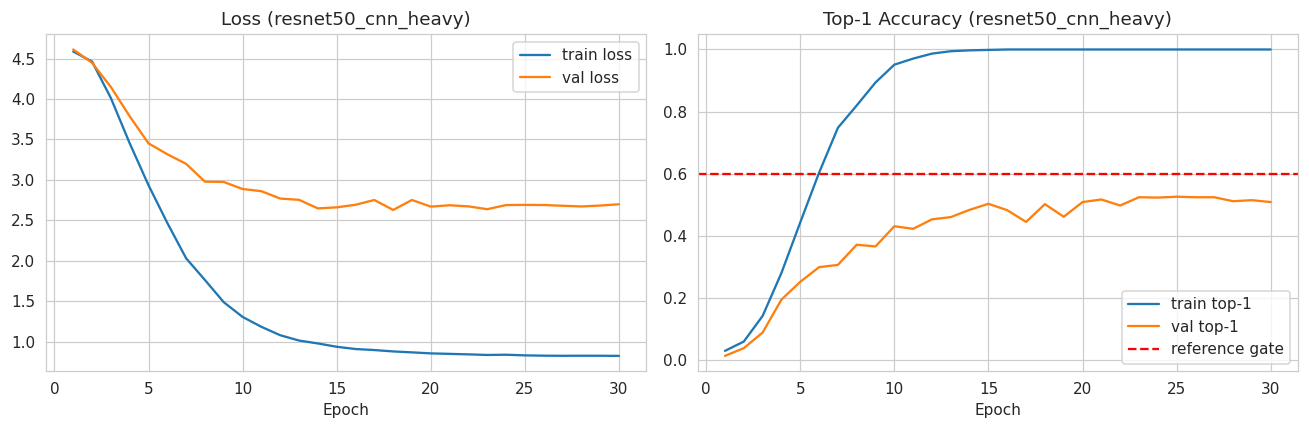

Best-checkpoint validation top-1: 0.526
Reference gate (0.60): not reached -- soft reference only, this notebook's primary output is the energy/carbon profile, not chasing this threshold


In [11]:
epochs_ran = [h["epoch"] for h in history]
train_loss = [h["train_loss"] for h in history]
val_loss_curve = [h["val_loss"] for h in history]
train_top1 = [h["train_top1"] for h in history]
val_top1_curve = [h["val_top1"] for h in history]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(epochs_ran, train_loss, label="train loss")
axes[0].plot(epochs_ran, val_loss_curve, label="val loss")
axes[0].set_title(f"Loss ({CONFIG.MODEL_TAG})"); axes[0].set_xlabel("Epoch"); axes[0].legend()

axes[1].plot(epochs_ran, train_top1, label="train top-1")
axes[1].plot(epochs_ran, val_top1_curve, label="val top-1")
axes[1].axhline(CONFIG.ACCURACY_GATE_THRESHOLD, color="red", linestyle="--", label="reference gate")
axes[1].set_title(f"Top-1 Accuracy ({CONFIG.MODEL_TAG})"); axes[1].set_xlabel("Epoch"); axes[1].legend()
plt.tight_layout()
plt.savefig(CONFIG.OUTPUT_DIR / f"{CONFIG.MODEL_TAG}_train_val_curves.png", dpi=130, bbox_inches="tight")
plt.show()

best_epoch_val_top1 = best_val_top1
print(f"Best-checkpoint validation top-1: {best_epoch_val_top1:.3f}")
print(f"Reference gate ({CONFIG.ACCURACY_GATE_THRESHOLD:.2f}): "
      f"{'reached' if best_epoch_val_top1 >= CONFIG.ACCURACY_GATE_THRESHOLD else 'not reached'} "
      f"-- soft reference only, this notebook's primary output is the energy/carbon profile, "
      f"not chasing this threshold")


## 9. Test-Set Evaluation & Inference Energy Profiling

Same protocol as notebook 1: one deterministic pass for accuracy, `CONFIG.INFERENCE_PROFILING_PASSES`
repeated passes for a stable energy-per-inference reading.

In [12]:
@torch.no_grad()
def collect_predictions(model, loader, device):
    model.eval()
    all_true, all_pred, all_top5 = [], [], []
    for frames, labels in loader:
        frames = frames.to(device)
        logits = model(frames)
        probs = torch.softmax(logits, dim=1).cpu().numpy()
        top1 = probs.argmax(axis=1)
        k = min(5, NUM_CLASSES)
        top5 = probs.argsort(axis=1)[:, ::-1][:, :k]
        all_true.extend(labels.numpy().tolist())
        all_pred.extend(top1.tolist())
        all_top5.append(top5)
    return {
        "y_true": np.array(all_true),
        "y_pred": np.array(all_pred),
        "top5": np.concatenate(all_top5, axis=0),
    }


# --- Accuracy pass: single, deterministic, this is the number reported for accuracy ---
test_preds = collect_predictions(model, test_loader, CONFIG.DEVICE)
test_top1 = (test_preds["y_true"] == test_preds["y_pred"]).mean()
test_top5 = np.mean([t in top5 for t, top5 in zip(test_preds["y_true"], test_preds["top5"])])
print(f"Test Top-1: {test_top1:.3f} | Test Top-5: {test_top5:.3f} | Test clips: {len(test_dataset)}")

_labels = list(range(NUM_CLASSES))
macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(
    test_preds["y_true"], test_preds["y_pred"], labels=_labels, average="macro", zero_division=0)
weighted_p, weighted_r, weighted_f1, _ = precision_recall_fscore_support(
    test_preds["y_true"], test_preds["y_pred"], labels=_labels, average="weighted", zero_division=0)
print(f"Macro F1: {macro_f1:.3f} | Weighted F1: {weighted_f1:.3f}")

# --- Energy-instrumented inference passes ---
# A single pass over a few hundred test clips is a short, noisy window for a
# power-sampling tracker like CodeCarbon. CONFIG.INFERENCE_PROFILING_PASSES repeats
# the full test-set pass to get a stabler average energy-per-inference reading.
# These repeated passes are NOT used for the accuracy numbers above (those stay a
# single deterministic pass) -- they exist purely to measure per-inference energy.
# Peak GPU memory and per-clip latency during inference (paper review Minor Issue #10:
# neither was reported anywhere in the original submission).
if torch.cuda.is_available():
    torch.cuda.reset_peak_memory_stats(CONFIG.DEVICE)

inference_energy_per_pass_kwh = []
inference_latency_seconds_per_pass = []
if CODECARBON_AVAILABLE:
    for pass_idx in range(CONFIG.INFERENCE_PROFILING_PASSES):
        tracker = EmissionsTracker(
            project_name=f"{CONFIG.MODEL_TAG}_inference_pass{pass_idx}",
            output_dir=str(CONFIG.OUTPUT_DIR), log_level="error",
            save_to_file=False, allow_multiple_runs=True,
        )
        tracker.start()
        _pass_t0 = time.time()
        with torch.no_grad():
            for frames, _ in test_loader:
                frames = frames.to(CONFIG.DEVICE)
                _ = model(frames)
        if torch.cuda.is_available():
            torch.cuda.synchronize()
        inference_latency_seconds_per_pass.append(time.time() - _pass_t0)
        tracker.stop()
        emissions_data = tracker.final_emissions_data
        if emissions_data is not None:
            inference_energy_per_pass_kwh.append(emissions_data.energy_consumed)

PEAK_INFERENCE_GPU_MEMORY_GB = (
    round(torch.cuda.max_memory_allocated(CONFIG.DEVICE) / (1024**3), 3)
    if torch.cuda.is_available() else None
)
LATENCY_MS_PER_CLIP = (
    float(np.mean(inference_latency_seconds_per_pass)) / len(test_dataset) * 1000
    if inference_latency_seconds_per_pass else None
)
print(f"Peak GPU memory during inference: {PEAK_INFERENCE_GPU_MEMORY_GB} GB"
      if PEAK_INFERENCE_GPU_MEMORY_GB is not None else "Peak GPU memory during inference: N/A (no GPU)")
print(f"Mean latency per single-clip inference: {LATENCY_MS_PER_CLIP:.2f} ms"
      if LATENCY_MS_PER_CLIP is not None else "Mean latency per single-clip inference: N/A")

if inference_energy_per_pass_kwh:
    MEAN_INFERENCE_ENERGY_PER_PASS_KWH = float(np.mean(inference_energy_per_pass_kwh))
    ENERGY_PER_CLIP_KWH = MEAN_INFERENCE_ENERGY_PER_PASS_KWH / len(test_dataset)
    print(f"\nMean energy per full test-set pass ({len(test_dataset)} clips): "
          f"{MEAN_INFERENCE_ENERGY_PER_PASS_KWH:.6f} kWh, across {len(inference_energy_per_pass_kwh)} passes")
    print(f"Estimated energy per single-clip inference: {ENERGY_PER_CLIP_KWH * 1e6:.2f} mWh")
else:
    MEAN_INFERENCE_ENERGY_PER_PASS_KWH = None
    ENERGY_PER_CLIP_KWH = None
    print("\nInference energy profiling skipped (codecarbon not installed).")


Test Top-1: 0.524 | Test Top-5: 0.797 | Test clips: 1409
Macro F1: 0.534 | Weighted F1: 0.535
Peak GPU memory during inference: 1.602 GB
Mean latency per single-clip inference: 48.02 ms

Mean energy per full test-set pass (1409 clips): 0.001873 kWh, across 3 passes
Estimated energy per single-clip inference: 1.33 mWh


### 9b. External Accuracy Reference Points (Not Reproduced Locally)

**Paper review Major Issue #3:** this study only compares its own five models against each
other. Without an external reference point, a reader cannot tell whether this notebook's
top-1 accuracy on the 100-class ASL Citizen pilot is competitive, mediocre, or unusually low
for the task -- the accuracy ceiling could reflect task difficulty at this scale just as
easily as an architectural or protocol limitation.

We do **not** reproduce these external numbers in this notebook (different class subsets,
splits, and training budgets make a like-for-like re-run out of scope for a single-model
green-computing unit), but they are recorded here so the number produced above can be read
in context rather than in isolation:

- **Alkhoraif et al. (2026)** report state-of-the-art accuracy on ASL Citizen (among other
  datasets) using a two-stream Swin-Transformer ensemble combining appearance and pose
  modalities -- a substantially heavier, multi-modal pipeline than any single model in this
  family.
- **Brettmann et al. (2025)** report that a VideoMAE-based ViViT variant substantially
  outperforms a traditional CNN baseline on WLASL100, a comparable-scale (100-class)
  word-level sign recognition benchmark.
- **Shawon et al. (2026)** compare VideoMAE, ViViT, and TimeSformer -- the same TimeSformer
  family used as this study's heavy Transformer entry -- on Bangla Sign Language datasets,
  finding video-Transformer accuracy sensitive to dataset size, frame rate, and signer
  variation.

None of these three report training or inference energy alongside their accuracy figures,
which is precisely the gap this five-model family's green-computing instrumentation exists
to fill -- but their accuracy numbers are the closest available external reference for
judging whether this notebook's own top-1 figure is in a reasonable range for a 100-class
word-level sign recognition task. A future revision could re-run one of these external
methods on this exact 100-class split to make the comparison direct rather than contextual.

## 10. Green-Computing Accounting — Carbon, Amortization, Efficiency

Same Eq. (1) / Eq. (2) / amortized-carbon math as notebook 1, using the same grid-intensity and
inference-volume constants — required for the two CNN notebooks' numbers to be comparable.

In [13]:
def fmt(value, spec=".4f", suffix=""):
    return "N/A" if value is None else f"{value:{spec}}{suffix}"


GRID_INTENSITY = CONFIG.GRID_CARBON_INTENSITY_KG_PER_KWH  # kg CO2e / kWh -- Eq. (1) in the proposal


def kwh_to_co2_kg(kwh):
    return None if kwh is None else kwh * GRID_INTENSITY


# --- Eq. (1): energy -> carbon ---
train_co2_kg_estimated = kwh_to_co2_kg(TOTAL_TRAIN_ENERGY_KWH)
inference_co2_kg_per_clip = kwh_to_co2_kg(ENERGY_PER_CLIP_KWH)

train_co2_g = None if train_co2_kg_estimated is None else train_co2_kg_estimated * 1000
inference_co2_mg_per_clip = None if inference_co2_kg_per_clip is None else inference_co2_kg_per_clip * 1e6

print("[Eq. 1] Estimated total training CO2e:", fmt(train_co2_g, ".2f", " g"),
      f"(grid intensity assumption: {GRID_INTENSITY} kg/kWh)")
print("[Eq. 1] Estimated CO2e per inference:", fmt(inference_co2_mg_per_clip, ".3f", " mg"))

# --- Faculty feedback: amortized training carbon / expected inference volume ---
# CONFIG.EXPECTED_INFERENCE_VOLUME is a placeholder deployment-scenario assumption
# (see CONFIG comment) -- swap in a properly justified/cited figure before this goes
# in the paper.
amortized_training_co2_per_inference_kg = None
if train_co2_kg_estimated is not None:
    amortized_training_co2_per_inference_kg = train_co2_kg_estimated / CONFIG.EXPECTED_INFERENCE_VOLUME

total_lifecycle_co2_per_inference_kg = None
if amortized_training_co2_per_inference_kg is not None and inference_co2_kg_per_clip is not None:
    total_lifecycle_co2_per_inference_kg = (
        amortized_training_co2_per_inference_kg + inference_co2_kg_per_clip
    )

amortized_mg = None if amortized_training_co2_per_inference_kg is None else amortized_training_co2_per_inference_kg * 1e6
lifecycle_mg = None if total_lifecycle_co2_per_inference_kg is None else total_lifecycle_co2_per_inference_kg * 1e6

print(f"\nAmortized training CO2e per inference "
      f"(assuming {CONFIG.EXPECTED_INFERENCE_VOLUME:,} lifetime inferences):", fmt(amortized_mg, ".4f", " mg"))
print("Total lifecycle CO2e per inference (amortized training + marginal inference):",
      fmt(lifecycle_mg, ".4f", " mg"))

# --- Eq. (2): accuracy-per-carbon efficiency metric ---
def efficiency_metric(accuracy_pct, co2_g):
    if co2_g is None or co2_g == 0:
        return None
    return accuracy_pct / co2_g


eta_train = efficiency_metric(test_top1 * 100, train_co2_g)
lifecycle_co2_g_per_inference = None if lifecycle_mg is None else lifecycle_mg / 1000
eta_lifecycle_per_inference = efficiency_metric(test_top1 * 100, lifecycle_co2_g_per_inference)

print("\n[Eq. 2] eta_acc/carbon (training-total basis):", fmt(eta_train, ".4f", " % per g CO2e"))
print("[Eq. 2] eta_acc/carbon (per-inference lifecycle basis):",
      fmt(eta_lifecycle_per_inference, ".6f", " % per g CO2e"))

# --- Lifecycle sensitivity analysis (paper review Recommended fix: the single 100,000-
# inference deployment-volume assumption was never sensitivity-tested in the original
# submission). Recomputes eta_life at each volume in CONFIG.DEPLOYMENT_VOLUME_SENSITIVITY
# so the model's efficiency ranking can be checked for stability across plausible scales,
# not just trusted at one arbitrary point estimate.
lifecycle_sensitivity = []
for n_inf in CONFIG.DEPLOYMENT_VOLUME_SENSITIVITY:
    amortized_kg_n = None if train_co2_kg_estimated is None else train_co2_kg_estimated / n_inf
    lifecycle_kg_n = None
    if amortized_kg_n is not None and inference_co2_kg_per_clip is not None:
        lifecycle_kg_n = amortized_kg_n + inference_co2_kg_per_clip
    lifecycle_g_n = None if lifecycle_kg_n is None else lifecycle_kg_n * 1000
    eta_life_n = efficiency_metric(test_top1 * 100, lifecycle_g_n)
    lifecycle_sensitivity.append({
        "deployment_volume_inferences": n_inf,
        "lifecycle_co2_mg_per_inference": None if lifecycle_kg_n is None else lifecycle_kg_n * 1e6,
        "eta_lifecycle_pct_per_g_co2e": eta_life_n,
    })

print("\n[Sensitivity] eta_life across deployment-volume assumptions (not just the single",
      f"{CONFIG.EXPECTED_INFERENCE_VOLUME:,}-inference point estimate):")
for row in lifecycle_sensitivity:
    print(f"  N={row['deployment_volume_inferences']:>10,}  "
          f"lifecycle_CO2e/inference={fmt(row['lifecycle_co2_mg_per_inference'], '.4f', ' mg')}  "
          f"eta_life={fmt(row['eta_lifecycle_pct_per_g_co2e'], '.6f', ' %/g CO2e')}")

# --- Parametric deployment-threshold check (paper review Minor Issue #7: the 60% soft
# accuracy reference is author-defined, not externally justified). Reports whether this
# model clears each candidate threshold rather than resting the deployment narrative on
# one unjustified line.
threshold_check = {
    f"clears_{int(t*100)}pct_threshold": bool(test_top1 >= t)
    for t in CONFIG.ACCURACY_GATE_THRESHOLDS_FOR_SENSITIVITY
}
print("\n[Sensitivity] Deployment-threshold check (test_top1 =", f"{test_top1:.3f}):")
for k, v in threshold_check.items():
    print(f"  {k}: {v}")


[Eq. 1] Estimated total training CO2e: 38.58 g (grid intensity assumption: 0.41272 kg/kWh)
[Eq. 1] Estimated CO2e per inference: 0.549 mg

Amortized training CO2e per inference (assuming 100,000 lifetime inferences): 0.3858 mg
Total lifecycle CO2e per inference (amortized training + marginal inference): 0.9345 mg

[Eq. 2] eta_acc/carbon (training-total basis): 1.3596 % per g CO2e
[Eq. 2] eta_acc/carbon (per-inference lifecycle basis): 56122.354443 % per g CO2e

[Sensitivity] eta_life across deployment-volume assumptions (not just the single 100,000-inference point estimate):
  N=    10,000  lifecycle_CO2e/inference=4.4065 mg  eta_life=11902.645696 %/g CO2e
  N=   100,000  lifecycle_CO2e/inference=0.9345 mg  eta_life=56122.354443 %/g CO2e
  N= 1,000,000  lifecycle_CO2e/inference=0.5873 mg  eta_life=89297.358397 %/g CO2e

[Sensitivity] Deployment-threshold check (test_top1 = 0.524):
  clears_50pct_threshold: True
  clears_60pct_threshold: False
  clears_70pct_threshold: False


## 10b. Multi-Seed Repetition for Statistical Validity

Repeats the full train+eval pipeline across `CONFIG.SEEDS` and reports mean +/- SD for every headline metric (paper review Major Issue #2). This is the single most compute-expensive addition in this notebook -- it multiplies total training cost by `len(CONFIG.SEEDS)`, which is itself worth reporting as part of this study's own carbon cost of doing rigorous science.

In [14]:
# --- Multi-seed repetition for statistical validity (paper review Major Issue #2: every
# comparative claim in the original single-run submission rested on n=1 per model, with
# no seeds, no variance, no CI anywhere -- self-disclosed but never fixed). The seed
# CONFIG.SEED run above (Sections 7-9) is reused as the first data point; this cell repeats
# the full train+eval pipeline for every remaining seed in CONFIG.SEEDS and reports
# mean +/- SD for every headline metric, so the model-vs-model rankings in the cross-model
# comparison can finally be checked against run-to-run noise.

MULTI_SEED_RESULTS = [{
    "seed": CONFIG.SEED,
    "test_top1": float(test_top1),
    "test_top5": float(test_top5),
    "best_val_top1": float(best_val_top1),
    "epochs_ran": len(history),
    "total_train_energy_kwh": TOTAL_TRAIN_ENERGY_KWH,
    "total_train_co2_g": train_co2_g,
    "eta_acc_per_carbon_training_basis": eta_train,
    "wall_clock_train_minutes": wall_clock_train_minutes,
    "peak_train_gpu_memory_gb": PEAK_TRAIN_GPU_MEMORY_GB,
}]


def _train_and_evaluate_one_seed(seed):
    """Rebuilds the model from scratch under a fresh seed, retrains it end-to-end with
    the same protocol as the primary run (Section 7), evaluates it, and returns the same
    headline metrics as the primary run's globals -- so it can be folded into
    MULTI_SEED_RESULTS on equal footing."""
    global model, optimizer, scheduler

    seed_everything(seed)
    model = CNNTemporalAvgSLRModel(num_classes=NUM_CLASSES).to(CONFIG.DEVICE)
    optimizer = torch.optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=CONFIG.LR, weight_decay=CONFIG.WEIGHT_DECAY,
    )
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=CONFIG.EPOCHS_FULL)

    _best_val_top1 = -float("inf")
    _epochs_without_improvement = 0
    _best_state_dict = None
    _per_epoch_energy_kwh = []
    _epochs_ran = 0

    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats(CONFIG.DEVICE)

    _t0 = time.time()
    for epoch in range(1, CONFIG.EPOCHS_FULL + 1):
        tracker = None
        if CODECARBON_AVAILABLE:
            tracker = EmissionsTracker(
                project_name=f"{CONFIG.MODEL_TAG}_seed{seed}_epoch{epoch}",
                output_dir=str(CONFIG.OUTPUT_DIR), log_level="error",
                save_to_file=False, allow_multiple_runs=True,
            )
            tracker.start()

        train_metrics = run_epoch(train_loader, train=True)
        val_metrics = run_epoch(val_loader, train=False)
        scheduler.step()
        _epochs_ran = epoch

        epoch_energy_kwh = None
        if tracker is not None:
            tracker.stop()
            emissions_data = tracker.final_emissions_data
            if emissions_data is not None:
                epoch_energy_kwh = emissions_data.energy_consumed
        if epoch_energy_kwh is not None:
            _per_epoch_energy_kwh.append(epoch_energy_kwh)

        is_best = val_metrics["top1"] > _best_val_top1
        if is_best:
            _best_val_top1 = val_metrics["top1"]
            _epochs_without_improvement = 0
            _best_state_dict = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            _epochs_without_improvement += 1
            if (epoch >= CONFIG.MIN_EPOCHS_BEFORE_STOPPING
                    and _epochs_without_improvement >= CONFIG.EARLY_STOPPING_PATIENCE):
                print(f"  [seed {seed}] early stopping at epoch {epoch}")
                break

    wall_min = (time.time() - _t0) / 60
    if _best_state_dict is not None:
        model.load_state_dict(_best_state_dict)
    model.eval()

    peak_train_mem_gb = (
        round(torch.cuda.max_memory_allocated(CONFIG.DEVICE) / (1024**3), 3)
        if torch.cuda.is_available() else None
    )
    total_train_energy_kwh = sum(_per_epoch_energy_kwh) if _per_epoch_energy_kwh else None

    preds = collect_predictions(model, test_loader, CONFIG.DEVICE)
    seed_test_top1 = float((preds["y_true"] == preds["y_pred"]).mean())
    seed_test_top5 = float(np.mean([t in top5 for t, top5 in zip(preds["y_true"], preds["top5"])]))

    train_co2_kg_seed = kwh_to_co2_kg(total_train_energy_kwh)
    train_co2_g_seed = None if train_co2_kg_seed is None else train_co2_kg_seed * 1000
    eta_train_seed = efficiency_metric(seed_test_top1 * 100, train_co2_g_seed)

    print(f"  [seed {seed}] test_top1={seed_test_top1:.3f} epochs={_epochs_ran} "
          f"train_co2_g={fmt(train_co2_g_seed, '.2f')} wall_min={wall_min:.1f}")

    return {
        "seed": seed,
        "test_top1": seed_test_top1,
        "test_top5": seed_test_top5,
        "best_val_top1": float(_best_val_top1),
        "epochs_ran": _epochs_ran,
        "total_train_energy_kwh": total_train_energy_kwh,
        "total_train_co2_g": train_co2_g_seed,
        "eta_acc_per_carbon_training_basis": eta_train_seed,
        "wall_clock_train_minutes": wall_min,
        "peak_train_gpu_memory_gb": peak_train_mem_gb,
    }


for _seed in CONFIG.SEEDS:
    if _seed == CONFIG.SEED:
        continue
    print(f"\n=== Repeating full train+eval for seed={_seed} ===")
    MULTI_SEED_RESULTS.append(_train_and_evaluate_one_seed(_seed))

# --- Aggregate mean +/- SD across all collected seeds ---
import statistics as _stats


def _mean_sd(metric_key):
    vals = [r[metric_key] for r in MULTI_SEED_RESULTS if r.get(metric_key) is not None]
    if not vals:
        return None, None
    if len(vals) == 1:
        return vals[0], 0.0
    return _stats.mean(vals), _stats.stdev(vals)


MULTI_SEED_SUMMARY = {"n_seeds": len(MULTI_SEED_RESULTS), "seeds": [r["seed"] for r in MULTI_SEED_RESULTS]}
for _k in ["test_top1", "test_top5", "total_train_co2_g", "eta_acc_per_carbon_training_basis",
           "total_train_energy_kwh", "wall_clock_train_minutes"]:
    _m, _s = _mean_sd(_k)
    MULTI_SEED_SUMMARY[f"{_k}_mean"] = _m
    MULTI_SEED_SUMMARY[f"{_k}_std"] = _s

print(f"\n=== Multi-seed summary (n={MULTI_SEED_SUMMARY['n_seeds']} seeds: {MULTI_SEED_SUMMARY['seeds']}) ===")
for _k, _v in MULTI_SEED_SUMMARY.items():
    if _k in ("n_seeds", "seeds"):
        continue
    print(f"  {_k}: {fmt(_v, '.4f')}")



=== Repeating full train+eval for seed=123 ===
  [seed 123] test_top1=0.519 epochs=30 train_co2_g=38.69 wall_min=58.3

=== Repeating full train+eval for seed=2024 ===
  [seed 2024] early stopping at epoch 30
  [seed 2024] test_top1=0.520 epochs=30 train_co2_g=38.69 wall_min=58.3

=== Multi-seed summary (n=3 seeds: [42, 123, 2024]) ===
  test_top1_mean: 0.5212
  test_top1_std: 0.0030
  test_top5_mean: 0.8027
  test_top5_std: 0.0050
  total_train_co2_g_mean: 38.6533
  total_train_co2_g_std: 0.0662
  eta_acc_per_carbon_training_basis_mean: 1.3483
  eta_acc_per_carbon_training_basis_std: 0.0099
  total_train_energy_kwh_mean: 0.0937
  total_train_energy_kwh_std: 0.0002
  wall_clock_train_minutes_mean: 58.2817
  wall_clock_train_minutes_std: 0.0412


## 11. Model Card Export

Saves `green_metrics_resnet50_cnn_heavy.json`, matching notebook 1's schema exactly.

In [15]:
model_card = {
    "model_tag": CONFIG.MODEL_TAG,
    "architecture_family": "CNN (heavy)",
    "backbone": "ResNet-50 (ImageNet-pretrained)",
    "num_classes": NUM_CLASSES,
    "top_k_classes_config": CONFIG.TOP_K_CLASSES,
    "frame_count": CONFIG.FRAME_COUNT,
    "image_size": CONFIG.IMAGE_SIZE,
    "params_total": n_params_total,
    "params_trainable": n_params_trainable,
    "gflops_per_inference": gflops_per_inference,
    "test_top1": float(test_top1),
    "test_top5": float(test_top5),
    "macro_f1": float(macro_f1),
    "weighted_f1": float(weighted_f1),
    "best_val_top1": float(best_val_top1),
    "epochs_ran": len(history),
    "wall_clock_train_minutes": wall_clock_train_minutes,
    "total_train_energy_kwh": TOTAL_TRAIN_ENERGY_KWH,
    "grid_carbon_intensity_kg_per_kwh": GRID_INTENSITY,
    "total_train_co2_g": train_co2_g,
    "energy_per_inference_kwh": ENERGY_PER_CLIP_KWH,
    "co2_per_inference_mg": inference_co2_mg_per_clip,
    "expected_inference_volume_assumption": CONFIG.EXPECTED_INFERENCE_VOLUME,
    "amortized_train_co2_per_inference_mg": amortized_mg,
    "total_lifecycle_co2_per_inference_mg": lifecycle_mg,
    "eta_acc_per_carbon_training_basis": eta_train,
    "eta_acc_per_carbon_lifecycle_basis": eta_lifecycle_per_inference,

    # --- Fields added in response to the paper review's Major/Minor issues ---
    "hardware_software_environment": HARDWARE_INFO,
    "signer_independence_report": SIGNER_INDEPENDENCE_REPORT,
    "peak_train_gpu_memory_gb": PEAK_TRAIN_GPU_MEMORY_GB,
    "peak_inference_gpu_memory_gb": PEAK_INFERENCE_GPU_MEMORY_GB,
    "latency_ms_per_clip_inference": LATENCY_MS_PER_CLIP,
    "lifecycle_carbon_sensitivity": lifecycle_sensitivity,
    "deployment_threshold_sensitivity": threshold_check,
    "multi_seed_results": MULTI_SEED_RESULTS,
    "multi_seed_summary": MULTI_SEED_SUMMARY,
    # Multi-seed mean/SD are the headline figures for cross-model comparison going
    # forward (paper review Major Issue #2) -- single-seed fields above are kept for
    # backward compatibility with the original schema, not as the primary result.
    "test_top1_mean": MULTI_SEED_SUMMARY.get("test_top1_mean"),
    "test_top1_std": MULTI_SEED_SUMMARY.get("test_top1_std"),
    "total_train_co2_g_mean": MULTI_SEED_SUMMARY.get("total_train_co2_g_mean"),
    "total_train_co2_g_std": MULTI_SEED_SUMMARY.get("total_train_co2_g_std"),
    "eta_acc_per_carbon_training_basis_mean": MULTI_SEED_SUMMARY.get("eta_acc_per_carbon_training_basis_mean"),
    "eta_acc_per_carbon_training_basis_std": MULTI_SEED_SUMMARY.get("eta_acc_per_carbon_training_basis_std"),
}

model_card_path = CONFIG.OUTPUT_DIR / f"green_metrics_{CONFIG.MODEL_TAG}.json"
with open(model_card_path, "w") as f:
    json.dump(model_card, f, indent=2)

print(f"Model card saved to: {model_card_path}")
print("Keep this JSON alongside green_metrics_mobilenet_v3_small_cnn_light.json from "
      "notebook 1 -- together they're the CNN half of the family (light vs. heavy). "
      "The Transformer-family and TinyMSLR notebooks will add three more.")
display(pd.DataFrame([model_card]).T.rename(columns={0: "value"}))


Model card saved to: /kaggle/working/green_report_resnet50_cnn_heavy/green_metrics_resnet50_cnn_heavy.json
Keep this JSON alongside green_metrics_mobilenet_v3_small_cnn_light.json from notebook 1 -- together they're the CNN half of the family (light vs. heavy). The Transformer-family and TinyMSLR notebooks will add three more.


,value
model_tag,resnet50_cnn_heavy
architecture_family,CNN (heavy)
backbone,ResNet-50 (ImageNet-pretrained)
num_classes,100
top_k_classes_config,100
frame_count,16
image_size,224
params_total,23712932
params_trainable,15169636
gflops_per_inference,132.214637


## 12. Notes for the Paper / Next Steps

- **CNN half of the family is done after this notebook** (light: MobileNetV3-Small, heavy:
  ResNet-50) — the first real comparison you can make is these two `green_metrics_*.json` files
  against each other: does ResNet-50's extra accuracy (if any) justify its extra energy/carbon
  cost? That's RQ2 in miniature, answerable as soon as both notebooks have run.
- **Next up:** small ViViT (lighter Transformer) — this is where the notebook family actually
  changes shape. The appearance-stream cache and manifest logic (Sections 1–4) carry over, but
  Section 5 needs real Transformer temporal-attention machinery instead of mean-pooling, so it
  won't be a near-copy of this notebook the way this one was of notebook 1. TimeSformer (heavier
  Transformer) after that, then TinyMSLR (distilled hybrid) last, once its source paper's method
  has been worked through.
- Numbers from this notebook are real once you run it on Kaggle — nothing above is pre-filled or
  asserted in advance.